# Clase 9/10 — Modulación LoRa en Python

Implementación paso a paso de los conceptos del artículo *Frequency Shift Chirp Modulation: The LoRa Modulation*, de Lorenzo Vangelista.

Material local: [PDF de la materia](../material_teorico/Frequency_Shift_Chirp_Modulation_The_LoRa_Modulation.pdf) y [apunte de teoría](../teoria/clase_9-10.md). Los enlaces relativos funcionan al navegar el proyecto local; en Colab se debe abrir o subir el material por separado.

## 1. Del vector de bits al símbolo entero

En la ecuación (1) del PDF, $w(nT_s)$ es un vector de $SF$ bits. Para cada instante de símbolo, se obtiene un entero mediante:

$$
s(nT_s)=\sum_{h=0}^{SF-1} w(nT_s)_h\,2^h.
$$

Cada componente se multiplica por su peso $2^h$ y luego se suman los resultados. El entero pertenece al conjunto $\{0,1,\ldots,2^{SF}-1\}$.

**Orden de los bits:** el componente de índice cero es el bit menos significativo (peso $2^0$). Por eso, `w = [1, 1, 0]` representa el número binario escrito habitualmente como `011`, es decir, el entero $3$.

En Python, representamos el vector con una lista y tomamos `SF = len(w)`. La función procesa un solo vector; no necesita recibir $n$ ni $T_s$ para hacer esta conversión.

In [1]:
def s(w):
    """Convierte bits ordenados de menor a mayor peso en un entero."""
    if len(w) == 0:
        raise ValueError("El vector debe contener al menos un bit.")
    if any(bit not in (0, 1) for bit in w):
        raise ValueError("Cada componente debe ser 0 o 1.")

    SF = len(w)
    simbolo = 0
    for h in range(SF):
        simbolo += int(w[h]) * (2 ** h)

    return simbolo

### Comprobación con un binario de 8 bits

Tomamos `10110010`, que equivale a $178$. La escritura habitual coloca el bit de mayor peso a la izquierda; para usar `s(w)` invertimos ese orden y construimos el vector con el bit de menor peso primero. Comparamos la sumatoria con la conversión de Python `int(binario, 2)`.

La duración de símbolo es $T_s = 2^{SF}/B$, con $SF$ igual a la cantidad de bits y $B$ en Hz. Usamos $B=125000$ Hz (125 kHz), modificable en el código. Para $SF=8$, resulta $T_s=0.002048$ s, es decir, $2.048$ ms. Esta duración depende de $SF$ y $B$, no del valor entero del símbolo.


In [2]:
binario = "10110010"
w = [int(bit) for bit in reversed(binario)]
SF = len(w)
B = 125_000  # Ancho de banda en Hz.
Ts = (2 ** SF) / B  # Duración de símbolo en segundos.

resultado = s(w)
esperado = int(binario, 2)

print(f"Binario de 8 bits: {binario}")
print(f"Vector w (menor peso primero): {w}")
print(f"s(w) = {resultado}; esperado = {esperado}")
print(f"SF = {SF}; B = {B} Hz; Ts = {Ts:.6f} s = {Ts * 1000:.3f} ms")
assert resultado == esperado
print("Comprobación correcta.")


Binario de 8 bits: 10110010
Vector w (menor peso primero): [0, 1, 0, 0, 1, 1, 0, 1]
s(w) = 178; esperado = 178
SF = 8; B = 125000 Hz; Ts = 0.002048 s = 2.048 ms
Comprobación correcta.


### Comprobación con un vector de números binarios

Guardamos varios números binarios de 8 bits como cadenas para conservar los ceros iniciales. Para cada uno construimos su vector de bits, aplicamos `s(w)` y verificamos el resultado con `int(..., 2)`. Incluimos cero, el máximo de 8 bits y valores intermedios.

También calculamos $SF$ y $T_s$ para cada vector, usando $B=125000$ Hz. Como todos tienen ocho bits y el mismo ancho de banda, sus duraciones son iguales: $2.048$ ms por símbolo.


In [3]:
binarios = ["00000000", "01010101", "10110010", "11111111"]

vectores_w = [[int(bit) for bit in reversed(binario)] for binario in binarios]
resultados = [s(w) for w in vectores_w]
esperados = [int(binario, 2) for binario in binarios]
B = 125_000  # Ancho de banda en Hz.
factores_sf = [len(w) for w in vectores_w]
duraciones_ts = [(2 ** SF) / B for SF in factores_sf]

for binario, resultado, esperado, SF, Ts in zip(
    binarios, resultados, esperados, factores_sf, duraciones_ts
):
    assert resultado == esperado, f"Falló la conversión de {binario}"
    print(f"{binario} -> {resultado}: correcto; SF = {SF}; Ts = {Ts:.6f} s = {Ts * 1000:.3f} ms")

print("Vector de enteros:", resultados)
print("Todas las comprobaciones fueron correctas.")


00000000 -> 0: correcto; SF = 8; Ts = 0.002048 s = 2.048 ms
01010101 -> 85: correcto; SF = 8; Ts = 0.002048 s = 2.048 ms
10110010 -> 178: correcto; SF = 8; Ts = 0.002048 s = 2.048 ms
11111111 -> 255: correcto; SF = 8; Ts = 0.002048 s = 2.048 ms
Vector de enteros: [0, 85, 178, 255]
Todas las comprobaciones fueron correctas.


## 2. Del número entero a la señal chirp

El entero obtenido con `s(w)` selecciona una forma de onda. Para un símbolo, escribimos $m=s(nT_s)$, $M=2^{SF}$ y $T=1/B$. Las ecuaciones (2) y (3) del PDF son:

$$
c(nT_s+kT)=\frac{1}{\sqrt{M}}\exp\left(j2\pi\frac{[(m+k)\bmod M]kTB}{M}\right)
=\frac{1}{\sqrt{M}}\exp\left(j2\pi\frac{[(m+k)\bmod M]k}{M}\right),
\qquad k=0,\ldots,M-1.
$$

La segunda expresión usa $TB=1$. Implementamos literalmente esta expresión discreta del artículo: `%` calcula el módulo, `1j` es la unidad imaginaria y `np.exp` calcula la exponencial compleja. El resultado son **muestras complejas en banda base**, no una señal real de radiofrecuencia.

La función `modular_simbolo(valor, SF, B, muestras_por_muestra=32)` calcula internamente $N=2^{SF}$ y devuelve `c, tiempo_vista, real, imaginaria, frecuencia_vista`. `fase_sierra` queda como auxiliar para integrar la frecuencia; toda la generación del símbolo se concentra en `modular_simbolo`. El tiempo local de las muestras discretas es `t = k / B`. Para el símbolo de índice $n$, el tiempo absoluto sería $nT_s+t$. La duración sigue siendo $T_s=M/B$; la última muestra está en $T_s-T$, porque no se incluye el comienzo del símbolo siguiente. El factor $1/\sqrt{M}$ hace que la suma de los módulos al cuadrado de las muestras sea uno.

Usamos la convención de fase de las ecuaciones citadas, sin sustituirla por otras expresiones de chirps de la bibliografía.

### Fase de la frecuencia en sierra, con sobremuestreo

Seguimos el código del compañero: conservamos las muestras de la ecuación (3) para el modulador y la FFT, y calculamos por separado la fase integrada de la frecuencia en sierra para los gráficos.

$$f(t)=\frac{B}{N}\big[(m+2Bt)\bmod N\big],\qquad N=2^{SF}.$$

La función `fase_sierra` devuelve la integral en **ciclos**; multiplicamos por $2\pi$ para obtener radianes y luego calculamos seno y coseno. La fase es continua aunque la frecuencia vuelva a cero al alcanzar $B$.

`modular_simbolo` devuelve las muestras discretas del PDF y los valores para la vista temporal. La vista usa `np.linspace(0, Ts, N * muestras_por_muestra + 1)`. Con un factor de 32 se calculan 32 intervalos por cada intervalo original. Incluimos el extremo $T_s$ para dibujar el símbolo completo; el chirp discreto conserva sus $N$ muestras y termina en $T_s-1/B$. El factor es ajustable con `MUESTRAS_POR_MUESTRA`.

Las curvas se dibujan con más puntos para visualizar mejor sus oscilaciones. El sobremuestreo de la vista no agrega información al chirp discreto ni cambia los datos utilizados por la FFT. Las partes real e imaginaria graficadas proceden de `fase_sierra`, como en el código del compañero. No se presupone que esta vista coincida con el chirp discreto del PDF para todos los símbolos; para las pruebas de FFT se usa siempre el chirp discreto.


### Validación de los parámetros

`validar_parametros_modulacion` reúne las comprobaciones de entrada. `modular_simbolo` la llama al inicio y luego calcula la señal. Si algún parámetro es inválido, se informa mediante `ValueError`.


In [4]:
import numpy as np


def validar_parametros_modulacion(valor, SF, B, muestras_por_muestra, N):
    """Valida el símbolo, SF, ancho de banda y factor de sobremuestreo."""
    if not isinstance(SF, (int, np.integer)) or SF < 1:
        raise ValueError("SF debe ser un entero positivo.")
    if not np.isfinite(B) or B <= 0:
        raise ValueError("B debe ser positivo y estar en Hz.")
    if not isinstance(muestras_por_muestra, (int, np.integer)) or muestras_por_muestra < 1:
        raise ValueError("El factor de sobremuestreo debe ser un entero positivo.")
    if not isinstance(valor, (int, np.integer)) or not 0 <= valor < N:
        raise ValueError(f"El símbolo debe ser un entero entre 0 y {N - 1}.")



In [5]:
import matplotlib.pyplot as plt


def fase_sierra(tiempo, simbolo, N, B):
    """Integral de la frecuencia en sierra, expresada en ciclos."""
    indice = simbolo + B * tiempo                           # Rampa hasta aplicar el modulo (comienza en el simbolo)
    ciclos_completos = np.floor(indice / N)                     # Aplicamos el modulo (se cuentan los ciclos completos)
    resto = np.mod(indice, N)                                   # Es el resto de los ciclos completos (lo que sobró al hacer el modulo)
    area_de_sierra = (ciclos_completos * N**2 + resto**2) / 2   # Calcula el área de la sierra (suma de áreas de triángulos)
    return (area_de_sierra - simbolo**2 / 2) / N          # Se resta simbolo**2/2 porque la rampa comienza en el simbolo, y se divide 
                                                                #     por 2N para convertir esa área en ciclos acumulados de la señal   

    """Basicamente me devuelve cuanto avanzo la fase desde t = 0 segun el simbolo y el tiempo transcurrido"""

def modular_simbolo(simbolo, SF, B, muestras_por_muestra=32):
    """Genera el chirp discreto y su vista temporal sobremuestreada."""
    N = 2 ** SF
    validar_parametros_modulacion(simbolo, SF, B, muestras_por_muestra, N) # Validación de parámetros de entrada


    # Muestras para el modulador y la FFT.
    k = np.arange(N)                                            # k = 0, 1, 2, ..., N-1
    fase_discreta = ((simbolo + k) % N) * k / N                 # Calcula la fase discreta para cada muestra
    c = np.exp(1j * 2 * np.pi * fase_discreta) / np.sqrt(N)     # Calcula la señal modulada en frecuencia (chirp) normalizada

    # Vista temporal: fase integrada de la frecuencia en sierra.
    # Permite graficar con mas detalle
    Ts = N / B
    tiempo_vista = np.linspace(0, Ts, N * muestras_por_muestra + 1)
    frecuencia_vista = np.mod(simbolo + B * tiempo_vista, N) * B / N
    fase = 2 * np.pi * fase_sierra(tiempo_vista, simbolo, N, B)
    real = np.cos(fase) / np.sqrt(N)
    imaginaria = np.sin(fase) / np.sqrt(N)
    return c, tiempo_vista, real, imaginaria, frecuencia_vista


### Ejemplo 1: binario de 8 bits, con sobremuestreo

Convertimos `10110010` con `s(w)` y aplicamos `modular_simbolo`. Con `MUESTRAS_POR_MUESTRA = 32`, el chirp discreto conserva 256 muestras y cada gráfico usa 8193 puntos, incluido el extremo del símbolo. Las partes real e imaginaria se calculan a partir de la fase integrada de la sierra, como en el código del compañero.

Podés cambiar el factor para comparar la suavidad de las curvas; con 1 la vista tiene los instantes originales más el extremo final. `B` sigue siendo 125000 Hz para el modelo discreto; la grilla de visualización tiene paso `1 / (B * MUESTRAS_POR_MUESTRA)`.


Símbolo: 178; SF: 8; muestras discretas: 256; puntos por gráfico: 8193; Ts: 2.048 ms
Comprobaciones correctas. Vista temporal con sobremuestreo.


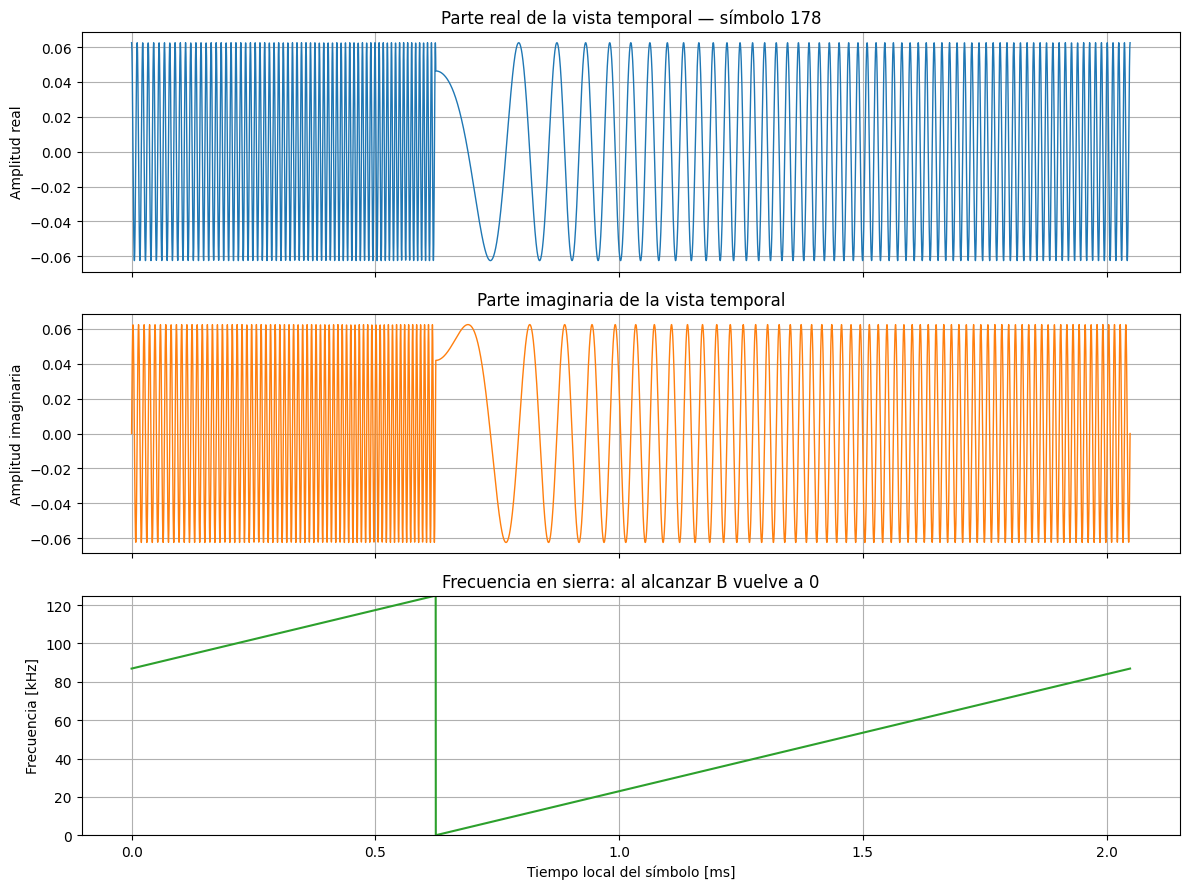

In [6]:
binario = "10110010"
w = [int(bit) for bit in reversed(binario)]
SF = len(w)
simbolo = s(w)
B = 125_000
N = 2 ** SF
T = 1 / B
Ts = N / B
k = np.arange(N)

MUESTRAS_POR_MUESTRA = 32
c, tiempo_vista, real, imaginaria, frecuencia_vista = modular_simbolo(
    simbolo, SF, B, MUESTRAS_POR_MUESTRA
)
c_ecuacion_2 = np.exp(
    1j * 2 * np.pi * ((simbolo + k) % N) * k * T * B / N
) / np.sqrt(N)
assert simbolo == 178
assert len(c) == N
assert len(tiempo_vista) == N * MUESTRAS_POR_MUESTRA + 1
assert np.allclose(c, c_ecuacion_2)
assert np.allclose(np.diff(tiempo_vista), T / MUESTRAS_POR_MUESTRA)
assert np.isclose(tiempo_vista[-1], Ts)
assert np.isclose(np.sum(np.abs(c) ** 2), 1)
assert np.allclose(real ** 2 + imaginaria ** 2, 1 / N)
assert np.all((frecuencia_vista >= 0) & (frecuencia_vista < B))
assert np.isclose(fase_sierra(0, simbolo, N, B), 0)
print(f"Símbolo: {simbolo}; SF: {SF}; muestras discretas: {len(c)}; puntos por gráfico: {len(tiempo_vista)}; Ts: {Ts * 1000:.3f} ms")
print("Comprobaciones correctas. Vista temporal con sobremuestreo.")

fig, ejes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
ejes[0].plot(tiempo_vista * 1000, real, linewidth=1)
ejes[0].set_title(f"Parte real de la vista temporal — símbolo {simbolo}")
ejes[0].set_ylabel("Amplitud real")
ejes[1].plot(tiempo_vista * 1000, imaginaria, linewidth=1, color="tab:orange")
ejes[1].set_title("Parte imaginaria de la vista temporal")
ejes[1].set_ylabel("Amplitud imaginaria")
ejes[2].plot(tiempo_vista * 1000, frecuencia_vista / 1000, color="tab:green")
ejes[2].set_title("Frecuencia en sierra: al alcanzar B vuelve a 0")
ejes[2].set_ylabel("Frecuencia [kHz]")
ejes[2].set_ylim(0, B / 1000)
ejes[2].set_xlabel("Tiempo local del símbolo [ms]")
for eje in ejes:
    eje.grid(True)
fig.tight_layout()
plt.show()


### Ejemplo 2: secuencia de símbolos — frecuencia versus tiempo

Transmitimos los elementos de `binarios` del punto 1 en su orden original. Cada símbolo ocupa su intervalo $T_s=2^{SF}/B$ y comienza al terminar el anterior. Desplazamos su tiempo local al tiempo acumulado de la secuencia. Las líneas verticales marcan los límites y cada tramo indica el binario y su entero.


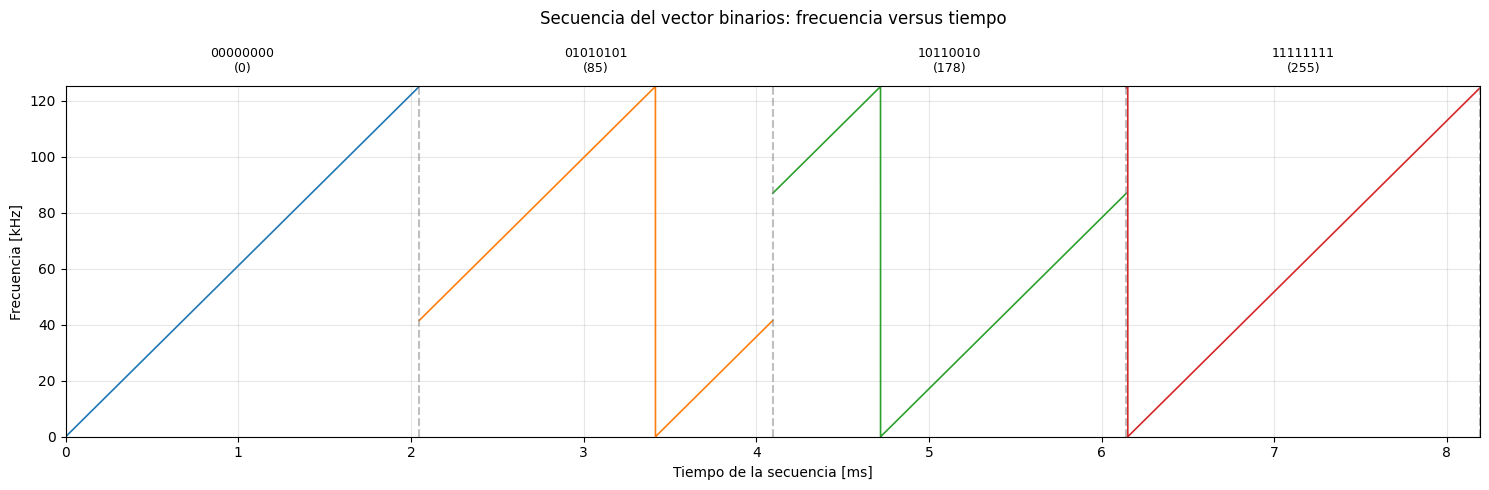

In [7]:
B = 125_000
MUESTRAS_POR_MUESTRA = 32

fig_secuencia, eje = plt.subplots(figsize=(15, 5))
tiempo_acumulado = 0.0
tiempos_secuencia = []
frecuencias_secuencia = []
limites_simbolos = [0.0]

for i, binario in enumerate(binarios):
    w = [int(bit) for bit in reversed(binario)]
    SF = len(w)
    simbolo = s(w)
    Ts = (2 ** SF) / B
    _, tiempo_vista, _, _, frecuencia_vista = modular_simbolo(
        simbolo, SF, B, MUESTRAS_POR_MUESTRA
    )

    # Omitimos el extremo final: pertenece al símbolo siguiente.
    tiempo_global = tiempo_acumulado + tiempo_vista[:-1]
    frecuencias = frecuencia_vista[:-1]
    tiempos_secuencia.append(tiempo_global)
    frecuencias_secuencia.append(frecuencias)
    eje.plot(tiempo_global * 1000, frecuencias / 1000,
             color=f"C{i % 10}", linewidth=1.2)
    eje.text((tiempo_acumulado + Ts / 2) * 1000, B / 1000 * 1.04,
             f"{binario}\n({simbolo})", ha="center", fontsize=9)

    tiempo_acumulado += Ts
    limites_simbolos.append(tiempo_acumulado)

tiempos_secuencia = np.concatenate(tiempos_secuencia)
frecuencias_secuencia = np.concatenate(frecuencias_secuencia)

for limite in limites_simbolos:
    eje.axvline(limite * 1000, color="gray", linestyle="--", alpha=0.5)

eje.set_title("Secuencia del vector binarios: frecuencia versus tiempo", pad=45)
eje.set_xlabel("Tiempo de la secuencia [ms]")
eje.set_ylabel("Frecuencia [kHz]")
eje.set_ylim(0, B / 1000)
eje.set_xlim(0, tiempo_acumulado * 1000)
eje.grid(True, alpha=0.3)
fig_secuencia.tight_layout()
plt.show()
